John S. Anvik, 2025  
University of Lethbridge Student ID: 001224816

### Import Packages

In [1]:
# Import packages
library(tidyverse)

options(repr.matrix.max.cols = Inf) # display all columns in tibbles

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


### Load and Trim Dataset

In [ ]:
# minizord.csv already removed non-songs, post-dawn, unmeasureable songs, acoustic outliers
# see "Data Preprocessing/01 preprocessing.ipynb"
data <- read_csv("data/minizord.csv")

# Only look at North data for now
data <- data %>% filter(neighbourhood == "centre") %>% ungroup()

Rows: 11694 Columns: 52
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (4): ID, IST, neighbourhood, Location_Number
dbl  (45): time_rel_sunrise, UST, D_M1_M2, D_M1_M3, D_M1_M4, D_M1_M5, D_M1_M...
lgl   (1): RepeatST
dttm  (1): DateTime
date  (1): date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


### Reformat Data: Row for each possible matching opportunity of focal male

In [ ]:
# Just focusing on one focal male for now (central male LbOW)
focal_id <- "KRDg"
focal_match_data <- data

In [ ]:
ids <- c("TbWY", "KRDg", "OPR", "WLpTb", "KLgK", "DgTbO") # Centre Ordered list of IDs correstponding to M1..M6
for (i in 1:6) {
    print(ids[[i]])
    for (d in unique(na.omit(filter(data, ID==ids[[i]])$date))) {
        print(d)
        print(nrow(filter(data, ID == ids[[i]], date == d)))
    }
}

[1] "TbWY"
[1] 19131
[1] 89
[1] 19132
[1] 123
[1] 19133
[1] 118
[1] 19135
[1] 139
[1] 19136
[1] 137
[1] "KRDg"
[1] 19131
[1] 209
[1] 19132
[1] 227
[1] 19133
[1] 189
[1] 19135
[1] 218
[1] 19136
[1] 190
[1] "OPR"
[1] 19131
[1] 195
[1] 19132
[1] 203
[1] 19133
[1] 139
[1] 19135
[1] 160
[1] 19136
[1] 178
[1] "WLpTb"
[1] 19131
[1] 194
[1] 19132
[1] 161
[1] 19133
[1] 135
[1] "KLgK"
[1] 19131
[1] 154
[1] 19132
[1] 109
[1] 19133
[1] 171
[1] 19136
[1] 122
[1] "DgTbO"
[1] 19131
[1] 255
[1] 19132
[1] 190
[1] 19133
[1] 183
[1] 19135
[1] 200
[1] 19136
[1] 172


In [ ]:
print(unique(na.omit(data$ID)))

[1] "DgTbO" "KLgK"  "KRDg"  "OPR"   "TbWY"  "WLpTb"


In [ ]:
# Make column for time since Male N's last song
# NA values at top of each day until that male sings
for (i in 1:6) {
    print(ids[[i]])
    time_last_song <- sprintf("time_M%i_last_song", i)
    time_since_last_song <- sprintf("time_since_M%i_last_song", i)
    print(time_last_song)
    focal_match_data <- focal_match_data %>%
    arrange(DateTime) %>%
    mutate("{time_last_song}" := if_else(ID == ids[[i]], time_rel_sunrise, NA)) %>%
    group_by(date) %>%
    fill({time_last_song}, .direction = "down") %>%
    mutate("{time_since_last_song}" := time_rel_sunrise - !!sym({time_last_song})) %>%
    ungroup()
}

[1] "TbWY"
[1] "time_M1_last_song"
[1] "KRDg"
[1] "time_M2_last_song"
[1] "OPR"
[1] "time_M3_last_song"
[1] "WLpTb"
[1] "time_M4_last_song"
[1] "KLgK"
[1] "time_M5_last_song"
[1] "DgTbO"
[1] "time_M6_last_song"


In [ ]:
# Male i's nth last song
N_MAX <- 3
for (n in 1:N_MAX) {
        for (i in 1:6) {
                n_last_song <- sprintf("M%i_%i_last_UST", i, n)
                time_last_song <- sprintf("time_M%i_%i_last_song", i, n)
                time_since_last_song <- sprintf("time_since_M%i_%i_last_song", i, n)
                focal_match_data <- focal_match_data %>%
                # Sort by ID and DateTime
                        group_by(ID) %>%
                        arrange(DateTime) %>%
                # Take the Nth last UST, set it to MX_Nth_last_UST
                        mutate("{n_last_song}" := if_else(ID == ids[[i]], lag(UST, n-1), NA)) %>%
                        # mutate("{time_last_song}" := if_else(ID == ids[[i]], time_rel_sunrise, NA)) %>%
                        mutate("{time_last_song}" := if_else(ID == ids[[i]], lag(time_rel_sunrise, n-1), NA)) %>%
                        ungroup() %>% 
                # Sort by DateTime, forward fill
                        group_by(date) %>%
                        arrange(DateTime) %>%
                        fill({n_last_song}, .direction = "down") %>%
                        fill({time_last_song}, .direction = "down") %>%
                # Since we don't want the current song to count as the 1st last song, recalculate last songs for rows where ID matches MX
                        group_by(ID, date) %>%
                        arrange(DateTime) %>%
                        mutate("{n_last_song}" := if_else(ID == ids[[i]], lag(UST, n), !!sym({n_last_song}))) %>%
                        mutate("{time_last_song}" := if_else(ID == ids[[i]], lag(time_rel_sunrise, n), !!sym({time_last_song}))) %>%
                        ungroup() %>% 
                # Calculate time since Nth last song
                        group_by(date) %>%
                        mutate("{time_since_last_song}" := time_rel_sunrise - !!sym({time_last_song})) %>%
                        ungroup()
        }
}

In [ ]:
tail(focal_match_data)

ID,DateTime,date,time_rel_sunrise,UST,IST,D_M1_M2,D_M1_M3,D_M1_M4,D_M1_M5,D_M1_M6,D_M2_M3,D_M2_M4,D_M2_M5,D_M2_M6,D_M3_M4,D_M3_M5,D_M3_M6,D_M4_M5,D_M4_M6,D_M5_M6,M1_Lat,M1_Lon,M2_Lat,M2_Lon,M3_Lat,M3_Lon,M4_Lat,M4_Lon,M5_Lat,M5_Lon,M6_Lat,M6_Lon,M1_last_UST,M2_last_UST,M3_last_UST,M4_last_UST,M5_last_UST,M6_last_UST,M1_match,M2_match,M3_match,M4_match,M5_match,M6_match,number_of_matches,does_it_match,neighbourhood,Location_Number,Time_Diff,RepeatST,Repeat_ST_Run,time_M1_last_song,time_since_M1_last_song,time_M2_last_song,time_since_M2_last_song,time_M3_last_song,time_since_M3_last_song,time_M4_last_song,time_since_M4_last_song,time_M5_last_song,time_since_M5_last_song,time_M6_last_song,time_since_M6_last_song,M1_1_last_UST,time_M1_1_last_song,time_since_M1_1_last_song,M2_1_last_UST,time_M2_1_last_song,time_since_M2_1_last_song,M3_1_last_UST,time_M3_1_last_song,time_since_M3_1_last_song,M4_1_last_UST,time_M4_1_last_song,time_since_M4_1_last_song,M5_1_last_UST,time_M5_1_last_song,time_since_M5_1_last_song,M6_1_last_UST,time_M6_1_last_song,time_since_M6_1_last_song,M1_2_last_UST,time_M1_2_last_song,time_since_M1_2_last_song,M2_2_last_UST,time_M2_2_last_song,time_since_M2_2_last_song,M3_2_last_UST,time_M3_2_last_song,time_since_M3_2_last_song,M4_2_last_UST,time_M4_2_last_song,time_since_M4_2_last_song,M5_2_last_UST,time_M5_2_last_song,time_since_M5_2_last_song,M6_2_last_UST,time_M6_2_last_song,time_since_M6_2_last_song,M1_3_last_UST,time_M1_3_last_song,time_since_M1_3_last_song,M2_3_last_UST,time_M2_3_last_song,time_since_M2_3_last_song,M3_3_last_UST,time_M3_3_last_song,time_since_M3_3_last_song,M4_3_last_UST,time_M4_3_last_song,time_since_M4_3_last_song,M5_3_last_UST,time_M5_3_last_song,time_since_M5_3_last_song,M6_3_last_UST,time_M6_3_last_song,time_since_M6_3_last_song
<chr>,<dttm>,<date>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
KRDg,2022-05-24 06:02:41,2022-05-24,581.7839,10,KRDg_7,58.73917,152.9006,NA,109.8957,131.403,184.9252,NA,98.00647,95.35512,NA,262.7032,277.7964,NA,NA,49.8128,17.97981,-67.16596,17.98032,-67.16582,17.97958,-67.16739,NA,NA,17.98002,-67.16495,17.98047,-67.16493,9,10,9,NA,7,25,0,0,0,0,0,0,0,0,centre,12,33,FALSE,1,-400.6541,982.4380,581.7839,0,8.249479,573.5344,NA,NA,-927.6592,1509.443,491.0882,90.69568,9,-400.6541,982.4380,105,548.0901,33.69377,9,8.249479,573.5344,NA,NA,NA,7,-927.6592,1509.443,25,491.0882,90.69568,13,-418.8581,1000.642,105,521.6761,60.10778,129,-8.856919,590.6408,NA,NA,NA,3,-939.9268,1521.711,25,430.0128,151.7711,9,-448.5084,1030.292,10,487.1468,94.63711,9,-27.05395,608.8378,NA,NA,NA,58,-950.6837,1532.468,25,386.5939,195.1900
KRDg,2022-05-24 06:02:54,2022-05-24,594.9857,NA,KRDg_U,58.73917,152.9006,NA,109.8957,131.403,184.9252,NA,98.00647,95.35512,NA,262.7032,277.7964,NA,NA,49.8128,17.97981,-67.16596,17.98032,-67.16582,17.97958,-67.16739,NA,NA,17.98002,-67.16495,17.98047,-67.16493,9,10,9,NA,7,25,0,0,0,0,0,0,0,0,centre,12,13,FALSE,1,-400.6541,995.6399,594.9857,0,8.249479,586.7362,NA,NA,-927.6592,1522.645,491.0882,103.89752,9,-400.6541,995.6399,10,581.7839,13.20184,9,8.249479,586.7362,NA,NA,NA,7,-927.6592,1522.645,25,491.0882,103.89752,13,-418.8581,1013.844,105,548.0901,46.89561,129,-8.856919,603.8426,NA,NA,NA,3,-939.9268,1534.913,25,430.0128,164.9730,9,-448.5084,1043.494,105,521.6761,73.30962,9,-27.05395,622.0397,NA,NA,NA,58,-950.6837,1545.669,25,386.5939,

[1] 1


`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
Warning message:
"Removed 5 rows containing non-finite outside the scale range (`stat_bin()`)."


[1] 2


`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
Warning message:
"Removed 5 rows containing non-finite outside the scale range (`stat_bin()`)."


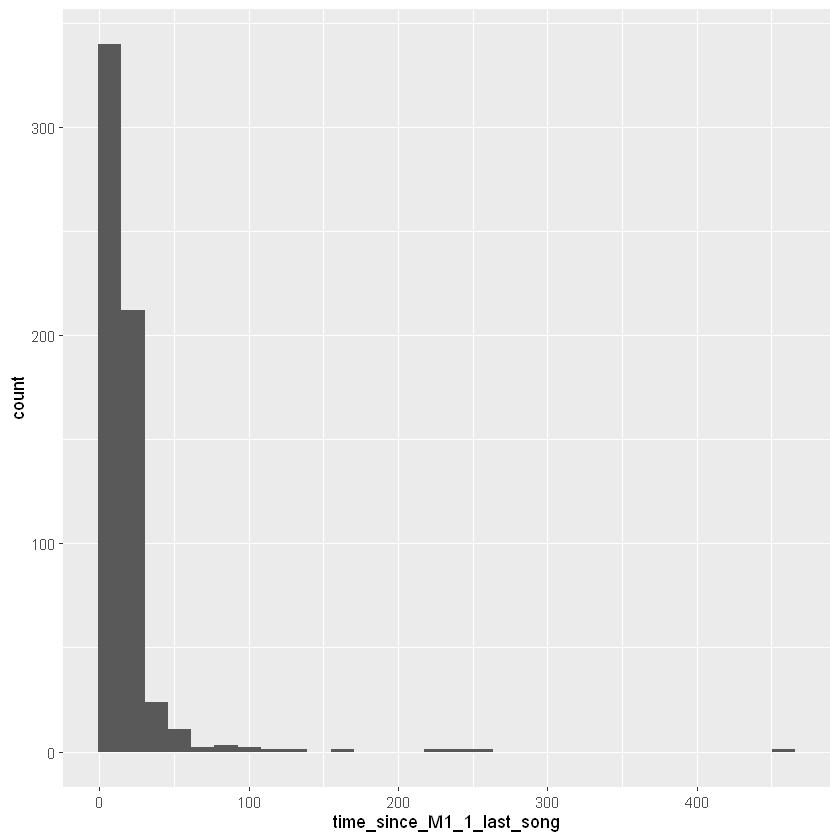

[1] 3


`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
Warning message:
"Removed 5 rows containing non-finite outside the scale range (`stat_bin()`)."


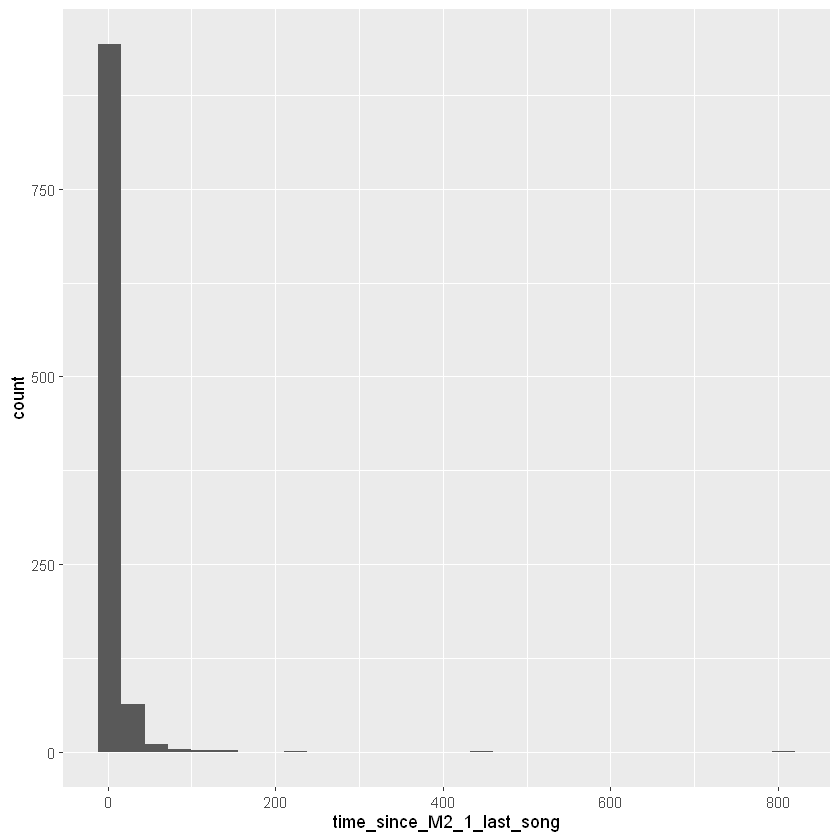

[1] 4


`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
Warning message:
"Removed 3 rows containing non-finite outside the scale range (`stat_bin()`)."


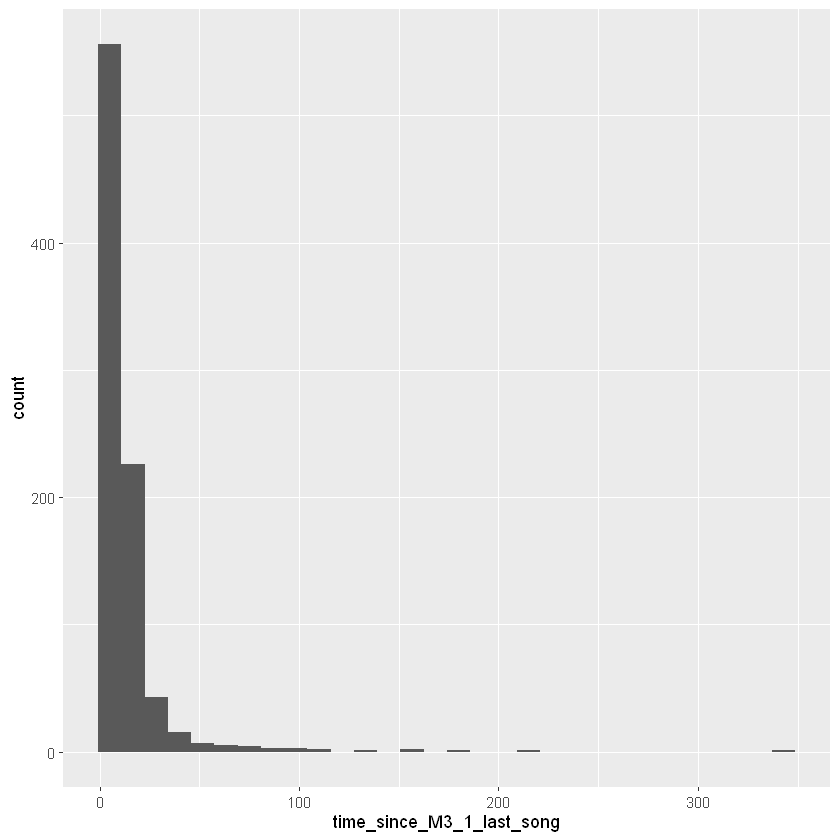

[1] 5


`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
Warning message:
"Removed 4 rows containing non-finite outside the scale range (`stat_bin()`)."


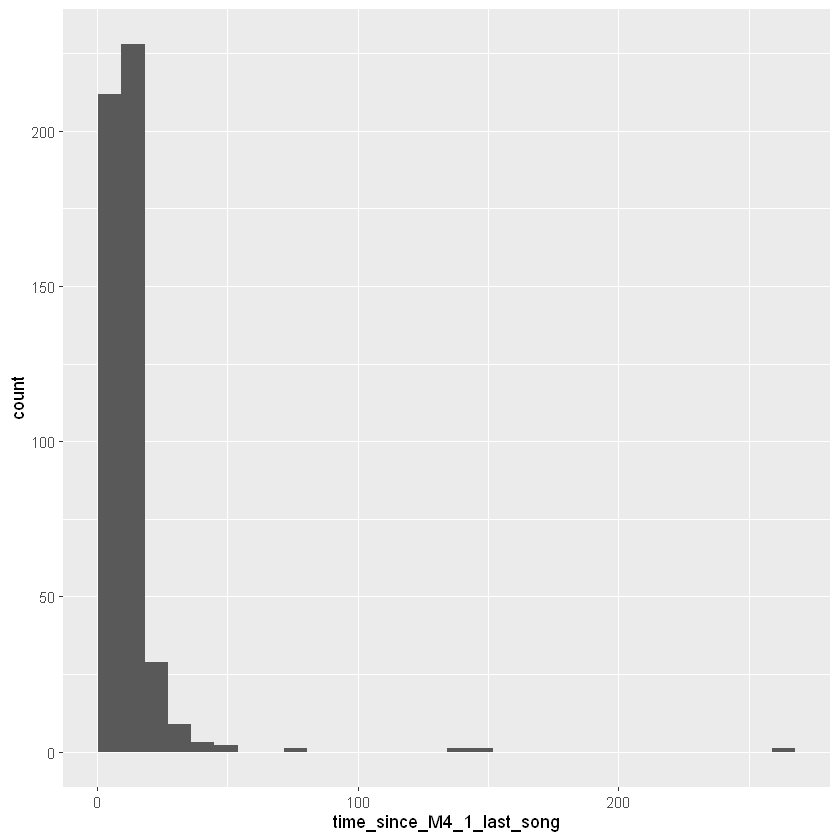

[1] 6


`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
Warning message:
"Removed 5 rows containing non-finite outside the scale range (`stat_bin()`)."


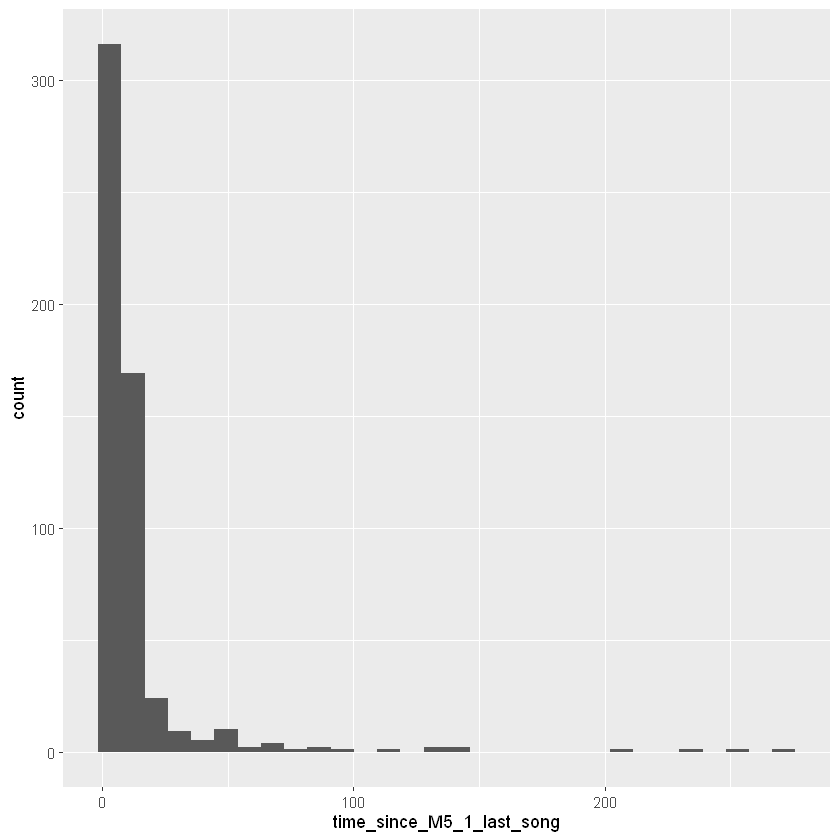

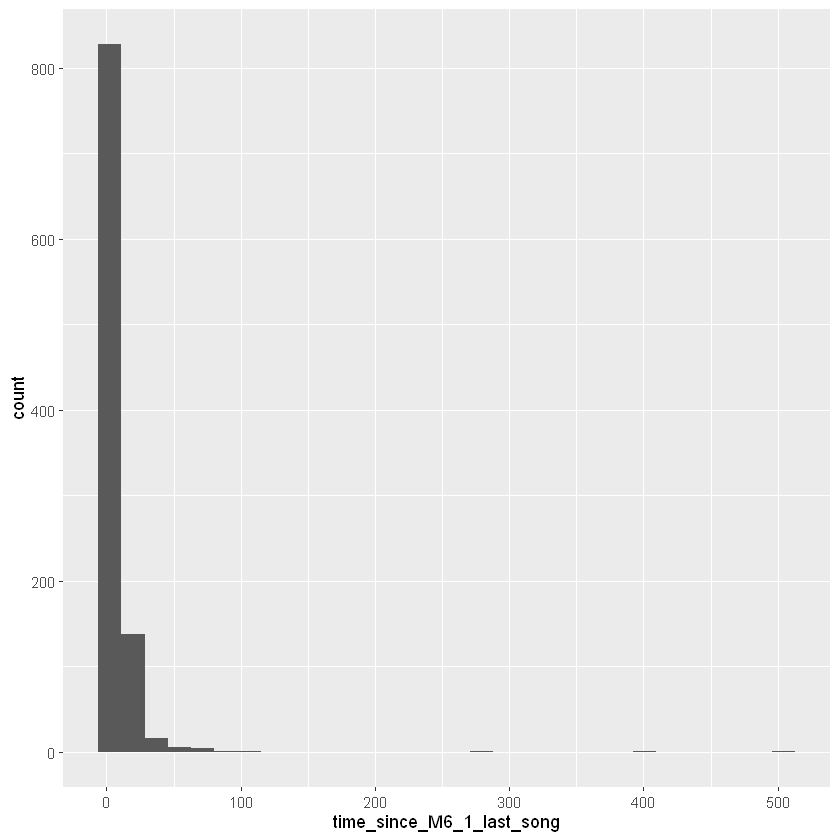

In [9]:
# How frequently do individuals typically sing?
for (i in 1:6) {
    print(i)
    plotting_data <- focal_match_data %>% 
        filter(ID == ids[[i]])
    plotting_column <- sprintf("time_since_M%i_1_last_song", i)
    plot <- ggplot(plotting_data) + 
        geom_histogram(aes(x=!!sym(plotting_column)))
    print(plot)
}

In [10]:
focal_match_data %>% select(contains("_1_last_song")) %>% select(contains("time_since")) %>% summary()
# focal_match_data %>% select(contains("_1_last_song")) %>% select(contains("time_since")) %>% quantile(probs=c(.1, .2, .3, .4, .5, .6, .7, .8, .9, 1), na.rm=TRUE)

 time_since_M1_1_last_song time_since_M2_1_last_song time_since_M3_1_last_song
 Min.   :  -0.7921         Min.   :  -0.9389         Min.   :  -0.8004        
 1st Qu.:   5.9920         1st Qu.:   2.8898         1st Qu.:   3.9590        
 Median :  10.9484         Median :   6.2041         Median :   7.2641        
 Mean   :  39.5102         Mean   :  36.1890         Mean   :  32.1306        
 3rd Qu.:  18.8002         3rd Qu.:  10.1296         3rd Qu.:  11.7291        
 Max.   :1063.5394         Max.   :1066.8352         Max.   :1185.2732        
 NA's   :86                NA's   :18                NA's   :6                
 time_since_M4_1_last_song time_since_M5_1_last_song time_since_M6_1_last_song
 Min.   :  0.04885         Min.   :  -0.8634         Min.   :  -0.9152        
 1st Qu.:  3.91471         1st Qu.:   3.6749         1st Qu.:   2.2180        
 Median :  7.21163         Median :   7.3766         Median :   5.5138        
 Mean   : 14.16806         Mean   :  75.3888        

In [11]:
tail(focal_match_data)

ID,DateTime,date,time_rel_sunrise,UST,IST,D_M1_M2,D_M1_M3,D_M1_M4,D_M1_M5,D_M1_M6,D_M2_M3,D_M2_M4,D_M2_M5,D_M2_M6,D_M3_M4,D_M3_M5,D_M3_M6,D_M4_M5,D_M4_M6,D_M5_M6,M1_Lat,M1_Lon,M2_Lat,M2_Lon,M3_Lat,M3_Lon,M4_Lat,M4_Lon,M5_Lat,M5_Lon,M6_Lat,M6_Lon,M1_last_UST,M2_last_UST,M3_last_UST,M4_last_UST,M5_last_UST,M6_last_UST,M1_match,M2_match,M3_match,M4_match,M5_match,M6_match,number_of_matches,does_it_match,neighbourhood,Location_Number,Time_Diff,RepeatST,Repeat_ST_Run,time_M1_last_song,time_since_M1_last_song,time_M2_last_song,time_since_M2_last_song,time_M3_last_song,time_since_M3_last_song,time_M4_last_song,time_since_M4_last_song,time_M5_last_song,time_since_M5_last_song,time_M6_last_song,time_since_M6_last_song,M1_1_last_UST,time_M1_1_last_song,time_since_M1_1_last_song,M2_1_last_UST,time_M2_1_last_song,time_since_M2_1_last_song,M3_1_last_UST,time_M3_1_last_song,time_since_M3_1_last_song,M4_1_last_UST,time_M4_1_last_song,time_since_M4_1_last_song,M5_1_last_UST,time_M5_1_last_song,time_since_M5_1_last_song,M6_1_last_UST,time_M6_1_last_song,time_since_M6_1_last_song,M1_2_last_UST,time_M1_2_last_song,time_since_M1_2_last_song,M2_2_last_UST,time_M2_2_last_song,time_since_M2_2_last_song,M3_2_last_UST,time_M3_2_last_song,time_since_M3_2_last_song,M4_2_last_UST,time_M4_2_last_song,time_since_M4_2_last_song,M5_2_last_UST,time_M5_2_last_song,time_since_M5_2_last_song,M6_2_last_UST,time_M6_2_last_song,time_since_M6_2_last_song,M1_3_last_UST,time_M1_3_last_song,time_since_M1_3_last_song,M2_3_last_UST,time_M2_3_last_song,time_since_M2_3_last_song,M3_3_last_UST,time_M3_3_last_song,time_since_M3_3_last_song,M4_3_last_UST,time_M4_3_last_song,time_since_M4_3_last_song,M5_3_last_UST,time_M5_3_last_song,time_since_M5_3_last_song,M6_3_last_UST,time_M6_3_last_song,time_since_M6_3_last_song
<chr>,<dttm>,<date>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
KRDg,2022-05-24 06:02:41,2022-05-24,581.7839,10,KRDg_7,58.73917,152.9006,NA,109.8957,131.403,184.9252,NA,98.00647,95.35512,NA,262.7032,277.7964,NA,NA,49.8128,17.97981,-67.16596,17.98032,-67.16582,17.97958,-67.16739,NA,NA,17.98002,-67.16495,17.98047,-67.16493,9,10,9,NA,7,25,0,0,0,0,0,0,0,0,centre,12,33,FALSE,1,-400.6541,982.4380,581.7839,0,8.249479,573.5344,NA,NA,-927.6592,1509.443,491.0882,90.69568,9,-400.6541,982.4380,105,548.0901,33.69377,9,8.249479,573.5344,NA,NA,NA,7,-927.6592,1509.443,25,491.0882,90.69568,13,-418.8581,1000.642,105,521.6761,60.10778,129,-8.856919,590.6408,NA,NA,NA,3,-939.9268,1521.711,25,430.0128,151.7711,9,-448.5084,1030.292,10,487.1468,94.63711,9,-27.05395,608.8378,NA,NA,NA,58,-950.6837,1532.468,25,386.5939,195.1900
KRDg,2022-05-24 06:02:54,2022-05-24,594.9857,NA,KRDg_U,58.73917,152.9006,NA,109.8957,131.403,184.9252,NA,98.00647,95.35512,NA,262.7032,277.7964,NA,NA,49.8128,17.97981,-67.16596,17.98032,-67.16582,17.97958,-67.16739,NA,NA,17.98002,-67.16495,17.98047,-67.16493,9,10,9,NA,7,25,0,0,0,0,0,0,0,0,centre,12,13,FALSE,1,-400.6541,995.6399,594.9857,0,8.249479,586.7362,NA,NA,-927.6592,1522.645,491.0882,103.89752,9,-400.6541,995.6399,10,581.7839,13.20184,9,8.249479,586.7362,NA,NA,NA,7,-927.6592,1522.645,25,491.0882,103.89752,13,-418.8581,1013.844,105,548.0901,46.89561,129,-8.856919,603.8426,NA,NA,NA,3,-939.9268,1534.913,25,430.0128,164.9730,9,-448.5084,1043.494,105,521.6761,73.30962,9,-27.05395,622.0397,NA,NA,NA,58,-950.6837,1545.669,25,386.5939,

In [12]:
# Focal Male's song-type repertoire
focal_repertoire <- unique(filter(data, ID == focal_id)$UST)
print("Focal Male's Song Type Repertoire:")
focal_repertoire

# Select only rows with focal male's songs
focal_match_data <- focal_match_data %>%
    filter(ID == focal_id) %>%
# Input variables: M1-M6's last UST, time since M1-M6 UST, # M2-M6's distance
    select(
        UST,
        DateTime, time_rel_sunrise,
        "D_M1_M2", "D_M1_M3", "D_M1_M4", "D_M1_M5", "D_M1_M6",
        "M1_last_UST", "M2_last_UST", "M3_last_UST", "M4_last_UST", "M5_last_UST", "M6_last_UST",
        
        contains("last_UST"), # Nth last song
        contains("last_song"), # Time since last song
        # time_M1_last_song, time_M2_last_song, time_M3_last_song, time_M4_last_song, time_M5_last_song, time_M6_last_song,
    	time_since_M1_last_song, time_since_M2_last_song, time_since_M3_last_song, time_since_M4_last_song, time_since_M5_last_song, time_since_M6_last_song, # did not include time since M1 last song because it is always 0
        number_of_matches, does_it_match
        # Also consider adding "streak"
    ) %>% 
    mutate(across(contains("UST"), ~ as.factor(.x)), 
        does_it_match = as.factor(does_it_match),
        number_of_matches = as.integer(number_of_matches)) %>%
# Set all neighbours' songs that aren't in M1's repertoire to 0
    mutate(across(contains("UST"), ~ if_else (.x %in% focal_repertoire, .x, as.factor(0)))) %>%
# Also set NA song types to 0, for all Males except M1
    mutate(across(contains("UST"), ~ if_else (is.na(.x), as.factor(0), .x)))

[1] "Focal Male's Song Type Repertoire:"


[1]  23  13  15 104  12  28 105  10  20   9   1   6   4   8 106 107  24 108  NA
[20] 109  25 110 111 112 113  33 114

In [13]:
# If song sung more than X*n seconds ago, set to 0
x <- 30

for (n in 1:N_MAX) {
        for (i in 1:6) {
                n_last_song <- sprintf("M%i_%i_last_UST", i, n)
                time_since_last_song <- sprintf("time_since_M%i_%i_last_song", i, n)
                focal_match_data <- focal_match_data %>%
                mutate("{n_last_song}" := if_else(!!sym({time_since_last_song}) > x*n, as.factor(0), !!sym({n_last_song})))
        }
}

`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
Warning message:
"Removed 19 rows containing non-finite outside the scale range (`stat_bin()`)."
`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
Warning message:
"Removed 5 rows containing non-finite outside the scale range (`stat_bin()`)."


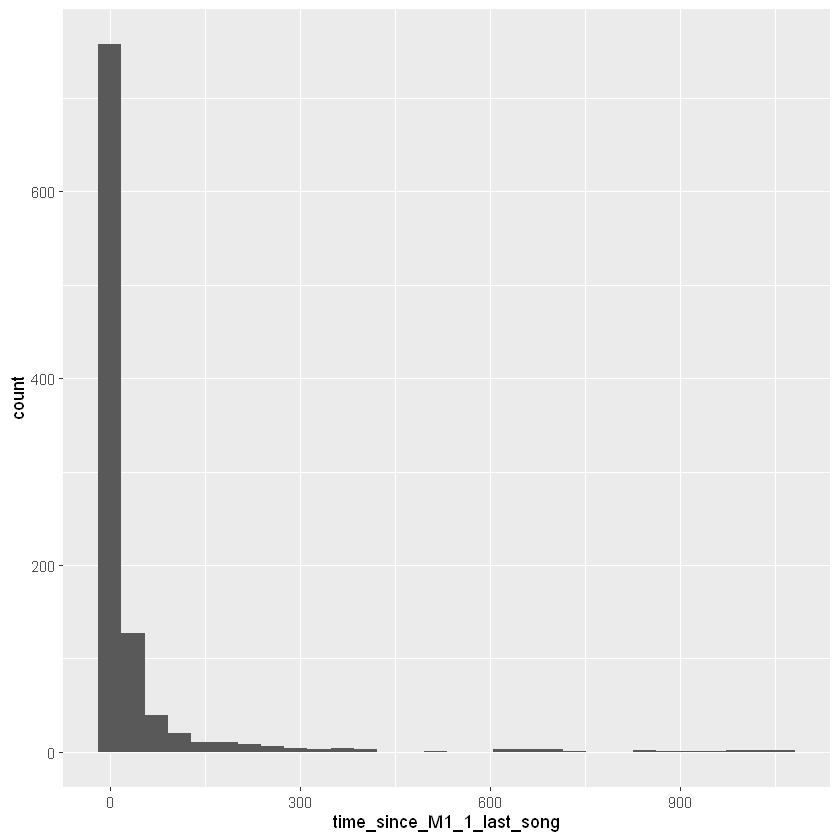

`stat_bin()` using `bins = 30`. Pick better value `binwidth`.


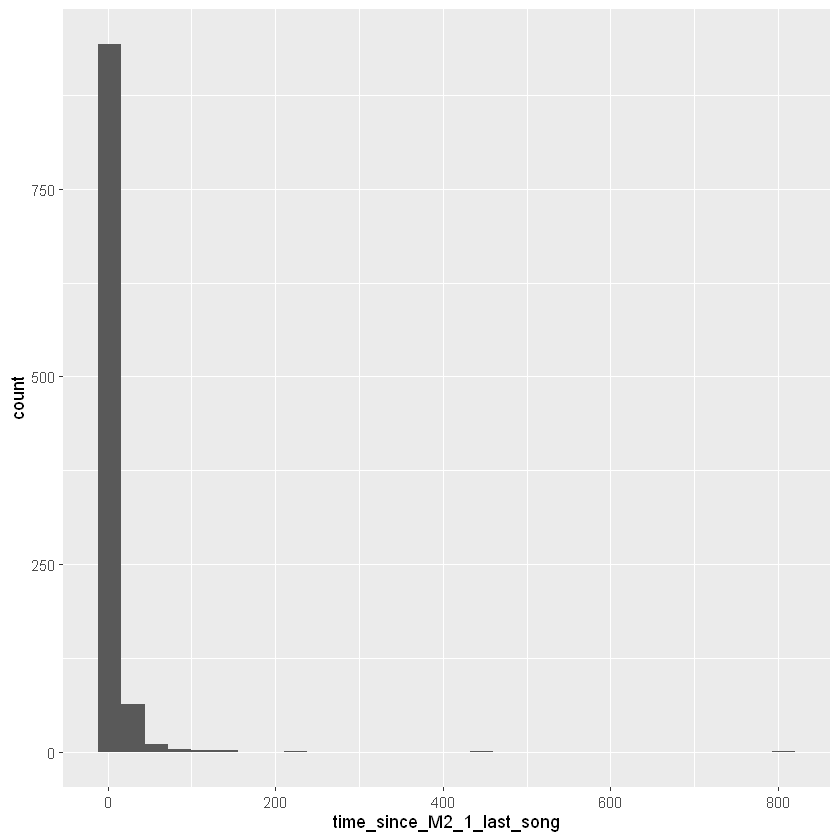

`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
Warning message:
"Removed 645 rows containing non-finite outside the scale range (`stat_bin()`)."


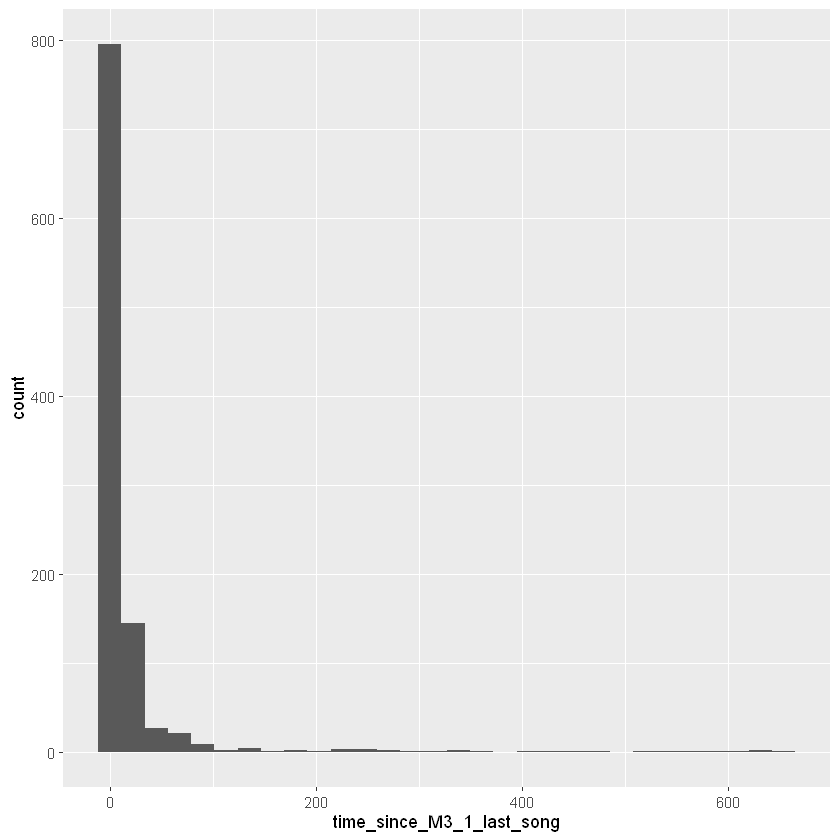

`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
Warning message:
"Removed 294 rows containing non-finite outside the scale range (`stat_bin()`)."


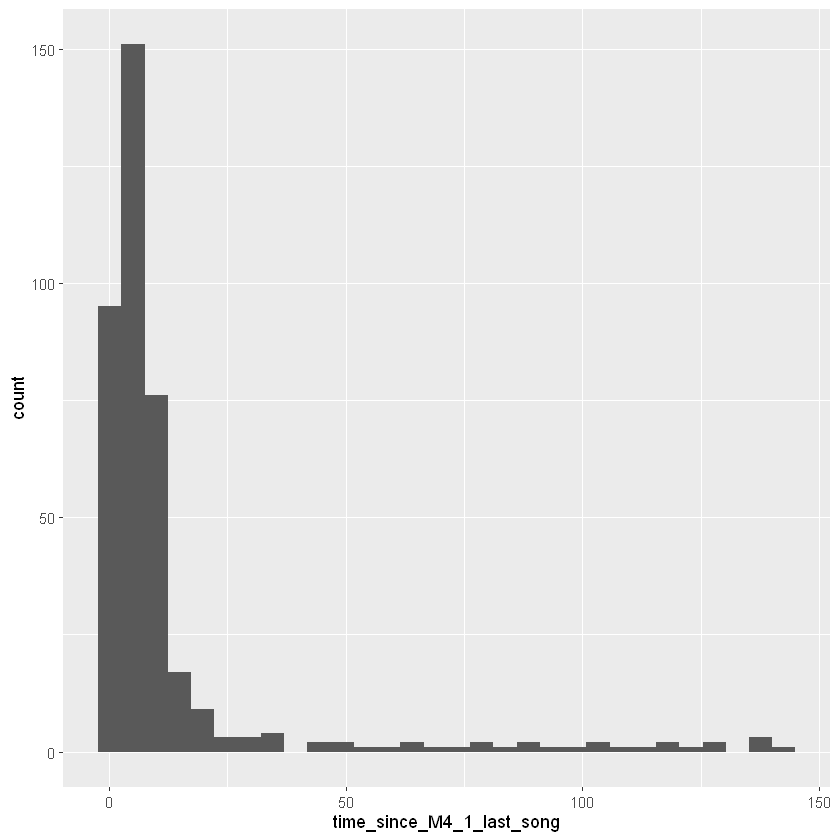

`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
Warning message:
"Removed 14 rows containing non-finite outside the scale range (`stat_bin()`)."


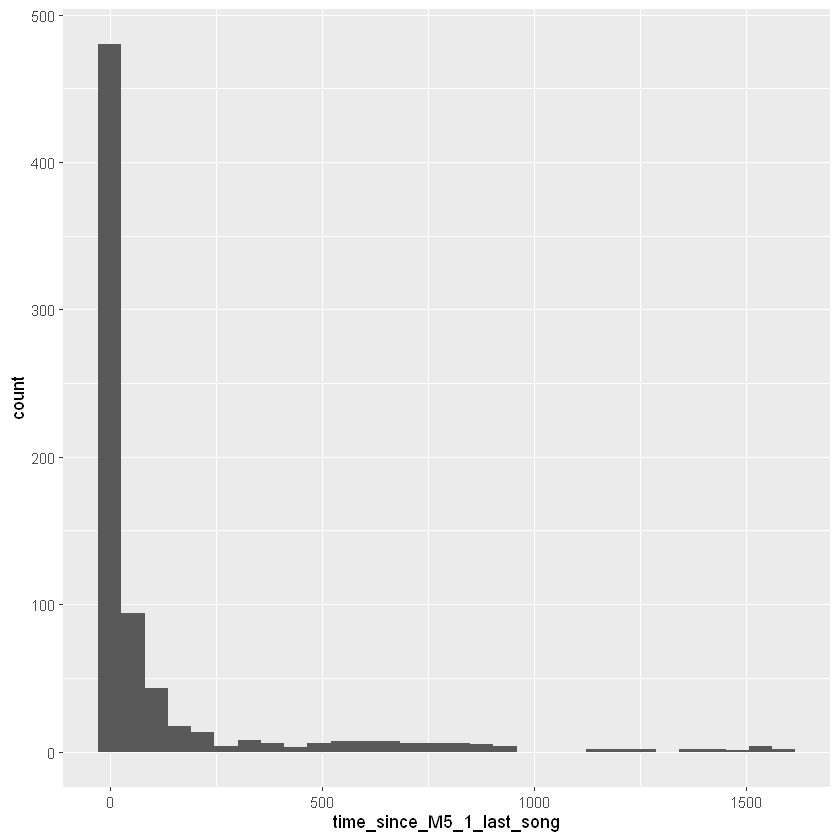

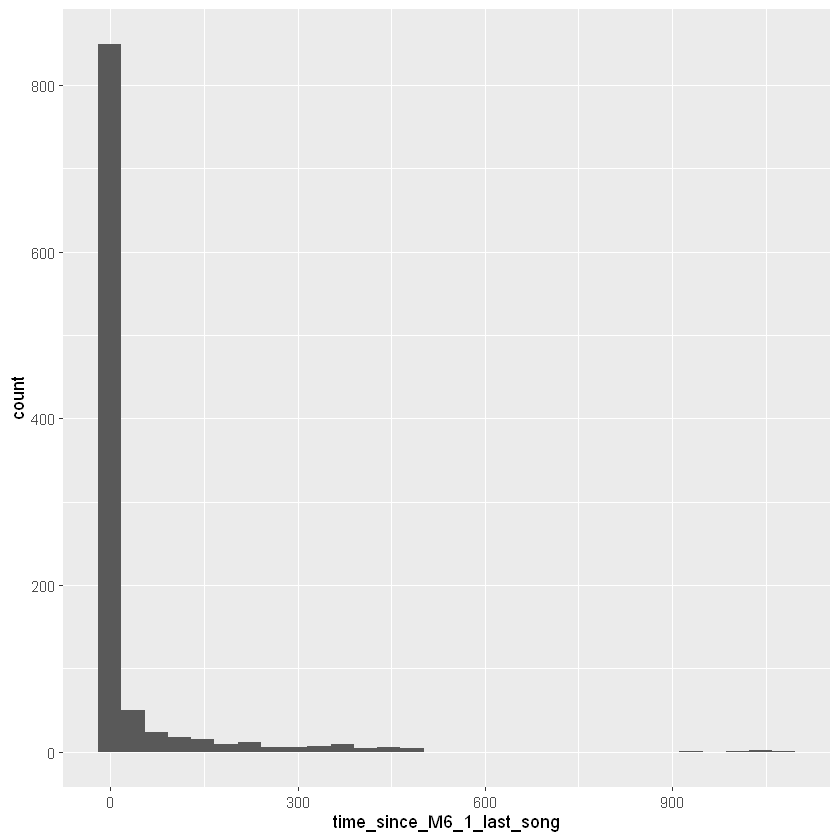

In [14]:
# How frequently do individuals typically sing?
for (i in 1:6) {
    plotting_column <- sprintf("time_since_M%i_1_last_song", i)
    plot <- ggplot(focal_match_data) + 
        geom_histogram(aes(x=!!sym(plotting_column)))
    print(plot)
}

In [15]:
# Compared to M2's repertoire, which songs are in the other males' repertoires?
# print("Male 2's Repertoire:")
# print(focal_repertoire)
for (i in 1:6) {
    print(sprintf("Male %i's Repertoire:", i))
    print(pull(unique(focal_match_data %>% select({sprintf("M%i_last_UST", i)}))))
    # print("\n")
}


[1] "Male 1's Repertoire:"
 [1] 0  13 15 10 9  20 4  6  23 12 1 
Levels: 0 1 4 5 6 9 10 11 12 13 15 20 23 32 101 102
[1] "Male 2's Repertoire:"
 [1] 23  13  15  104 12  28  105 10  20  9   1   6   4   8   106 107 24  108 0  
[20] 109 25  110 111 112 113 33  114
27 Levels: 0 1 4 6 8 9 10 12 13 15 20 23 24 25 28 33 104 105 106 107 ... 114
[1] "Male 3's Repertoire:"
[1] 0  9  10
21 Levels: 0 9 10 26 34 35 121 122 123 124 125 126 127 128 129 130 132 ... 136
[1] "Male 4's Repertoire:"
 [1] 0  8  23 4  1  20 10 13 6  24 15 25
Levels: 0 1 4 5 6 7 8 10 13 15 20 23 24 25 26 83 84 86 87 88 89
[1] "Male 5's Repertoire:"
 [1] 0  10 13 15 1  12 4  6  9  8 
Levels: 0 1 4 5 6 7 8 9 10 11 12 13 14 15 55 56 57 58 59
[1] "Male 6's Repertoire:"
 [1] 0  33 10 15 1  20 12 4  8  25 6 
26 Levels: 0 1 4 5 6 7 8 10 11 12 15 20 25 30 32 33 153 154 155 158 159 ... 164


In [16]:
tail(focal_match_data)

UST,DateTime,time_rel_sunrise,D_M1_M2,D_M1_M3,D_M1_M4,D_M1_M5,D_M1_M6,M1_last_UST,M2_last_UST,M3_last_UST,M4_last_UST,M5_last_UST,M6_last_UST,M1_1_last_UST,M2_1_last_UST,M3_1_last_UST,M4_1_last_UST,M5_1_last_UST,M6_1_last_UST,M1_2_last_UST,M2_2_last_UST,M3_2_last_UST,M4_2_last_UST,M5_2_last_UST,M6_2_last_UST,M1_3_last_UST,M2_3_last_UST,M3_3_last_UST,M4_3_last_UST,M5_3_last_UST,M6_3_last_UST,time_M1_last_song,time_since_M1_last_song,time_M2_last_song,time_since_M2_last_song,time_M3_last_song,time_since_M3_last_song,time_M4_last_song,time_since_M4_last_song,time_M5_last_song,time_since_M5_last_song,time_M6_last_song,time_since_M6_last_song,time_M1_1_last_song,time_since_M1_1_last_song,time_M2_1_last_song,time_since_M2_1_last_song,time_M3_1_last_song,time_since_M3_1_last_song,time_M4_1_last_song,time_since_M4_1_last_song,time_M5_1_last_song,time_since_M5_1_last_song,time_M6_1_last_song,time_since_M6_1_last_song,time_M1_2_last_song,time_since_M1_2_last_song,time_M2_2_last_song,time_since_M2_2_last_song,time_M3_2_last_song,time_since_M3_2_last_song,time_M4_2_last_song,time_since_M4_2_last_song,time_M5_2_last_song,time_since_M5_2_last_song,time_M6_2_last_song,time_since_M6_2_last_song,time_M1_3_last_song,time_since_M1_3_last_song,time_M2_3_last_song,time_since_M2_3_last_song,time_M3_3_last_song,time_since_M3_3_last_song,time_M4_3_last_song,time_since_M4_3_last_song,time_M5_3_last_song,time_since_M5_3_last_song,time_M6_3_last_song,time_since_M6_3_last_song,number_of_matches,does_it_match
<fct>,<dttm>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<fct>
10,2022-05-24 06:02:41,581.7839,58.73917,152.9006,NA,109.8957,131.403,9,10,9,0,0,25,0,0,0,NA,0,0,0,0,0,NA,0,0,0,0,0,NA,0,0,-400.6541,982.4380,581.7839,0,8.249479,573.5344,NA,NA,-927.6592,1509.443,491.0882,90.69568,-400.6541,982.4380,548.0901,33.69377,8.249479,573.5344,NA,NA,-927.6592,1509.443,491.0882,90.69568,-418.8581,1000.642,521.6761,60.10778,-8.856919,590.6408,NA,NA,-939.9268,1521.711,430.0128,151.7711,-448.5084,1030.292,487.1468,94.63711,-27.05395,608.8378,NA,NA,-950.6837,1532.468,386.5939,195.1900,0,0
0,2022-05-24 06:02:54,594.9857,58.73917,152.9006,NA,109.8957,131.403,9,10,9,0,0,25,0,10,0,NA,0,0,0,105,0,NA,0,0,0,105,0,NA,0,0,-400.6541,995.6399,594.9857,0,8.249479,586.7362,NA,NA,-927.6592,1522.645,491.0882,103.89752,-400.6541,995.6399,581.7839,13.20184,8.249479,586.7362,NA,NA,-927.6592,1522.645,491.0882,103.89752,-418.8581,1013.844,548.0901,46.89561,-8.856919,603.8426,NA,NA,-939.9268,1534.913,430.0128,164.9730,-448.5084,1043.494,521.6761,73.30962,-27.05395,622.0397,NA,NA,-950.6837,1545.669,386.5939,208.3919,0,0
110,2022-05-24 06:03:12,612.1459,58.73917,152.9006,NA,109.8957,131.403,9,110,9,0,0,25,0,0,0,NA,0,0,0,10,0,NA,0,0,0,105,0,NA,0,0,-400.6541,1012.8001,612.1459,0,8.249479,603.8964,NA,NA,-927.6592,1539.805,491.0882,121.05770,-400.6541,1012.8001,594.9857,17.16018,8.249479,603.8964,NA,NA,-927.6592,1539.805,491.0882,121.05770,-418.8581,1031.004,581.7839,30.36202,-8.856919,621.0028,NA,NA,-939.9268,1552.073,430.0128,182.1332,-448.5084,1060.654,548.0901,64.05579,-27.05395,639.1999,NA,NA,-950.6837,1562.830,386.5939,225.5520,0,0
13,2022-05-24 06:03:31,631.4317,58.73917,152.9006,NA,109.8957,131.403,9,13,9,0,0,25,0,110,0,NA,0,0,0,0,0,NA,0,0,0,10,0,NA,0,0,-400.6541,1032.0858,631.4317,0,8.249479,623.1822,NA,NA,-927.6592,1559.091,491.0882,140.34345,-400.6541,1032.0858,612.1459,19.28575,8.249479,623.1822,NA,NA,-927.6592,1559.091,491.0882,140.34345,-418.8581,1050.290,594.9857,36.44593,-8.856919,640.2886,NA,NA,-939.9268,1571.358,430.0128,201.4189,-448.5084,1079.940,581.783

### Export Data

In [18]:
write_csv(focal_match_data, "data/centre_matching_opportunities.csv")